## Import packages

In [1]:
import os
import kagglehub
import glob
import numpy as np
import pandas as pd
import pathlib
import torch
import torch.nn as nn
from datasets import Dataset, DatasetDict
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding, pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
from collections import Counter

import warnings
warnings.filterwarnings("ignore")

## Inputs

In [2]:
INPUT_DIR = pathlib.Path("/kaggle/input")

COMPETITIONS_DIR = sorted([
    p for p in (INPUT_DIR / "competitions").iterdir()
    if p.is_dir()
])

DATASET_DIR = sorted([
    p for p in (INPUT_DIR / "datasets").iterdir()
    if p.is_dir()
])

MODEL_DIR = sorted([
    p for p in (INPUT_DIR / "models").iterdir()
    if p.is_dir()
])


NOTEBOOK_DIR = sorted([
    p for p in (INPUT_DIR / "notebooks").iterdir()
    if p.is_dir()
])

print("Competitions directories:", len(COMPETITIONS_DIR))
for path in COMPETITIONS_DIR:
    for file_path in path.rglob("*"):
        if file_path.is_file():
            path_str = str(file_path)
            print(path_str)
    
print("\nDataset directories:", len(DATASET_DIR))
for path in DATASET_DIR:
    print(path)

print("\nModel directories:", len(MODEL_DIR))
for path in MODEL_DIR:
    print(path)

print("\nNotebook directories:", len(NOTEBOOK_DIR))
for path in NOTEBOOK_DIR:
    print(path)

Competitions directories: 1
/kaggle/input/competitions/name-that-llm/sample_submission.parquet
/kaggle/input/competitions/name-that-llm/train.csv
/kaggle/input/competitions/name-that-llm/test.csv

Dataset directories: 1
/kaggle/input/datasets/pawankumargunjan

Model directories: 1
/kaggle/input/models/answer-ai

Notebook directories: 1
/kaggle/input/notebooks/pawankumargunjan


## Read the datasets

In [3]:
# competitions training data
TRAIN_PATH = (
    INPUT_DIR / "competitions/name-that-llm/train.csv"
)

# Original competition dataset
train_df = pd.read_csv(TRAIN_PATH)
print("Original training shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())
print("Classes:", train_df["model"].nunique())

VALID_LABELS = set(train_df["model"].dropna().unique())
train_df.head()

Original training shape: (2699, 4)
Columns: ['id', 'prompt_id', 'text', 'model']
Classes: 18


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [4]:
VALID_MODEL_NAMES = set(train_df['model'].unique())

# # Create label mappings if your 'model' column contains strings
# label2id = {model: i for i, model in enumerate(VALID_MODEL_NAMES)}
# id2label = {i: model for i, model in enumerate(VALID_MODEL_NAMES)}

# id2label
print(VALID_MODEL_NAMES)

{'claude-sonnet-5', 'claude-opus-4-8', 'claude-opus-5', 'glm-5.3-flash', 'glm-5.3', 'claude-opus-4-6', 'gpt-5.6-terra', 'gemini-3.6-flash', 'gemini-3.8-flash', 'gpt-5.6-sol', 'gemini-3.7-flash', 'gemini-3.1-pro-preview', 'claude-fable-5', 'gpt-5.5', 'kimi-k3', 'gpt-6-astra', 'gpt-5.6-luna', 'qwen3.8-max'}


### Extra Data

In [5]:
# competitions training data
FINAL_DATASET_PATH = (
    INPUT_DIR / "datasets/pawankumargunjan/name-that-llm-consolidated/train_english.csv"
)
consolidated_df = pd.read_csv(FINAL_DATASET_PATH)

print("Dataset shape:", consolidated_df.shape)
print("Columns:", consolidated_df.columns.tolist())

display(consolidated_df.head())

Dataset shape: (203670, 4)
Columns: ['text', 'model', 'text_length', 'language']


,text,model,text_length,language
0,A single photon leaves a distant star and trav...,gpt-6-astra,1031,en
1,"There is a hum where a heartbeat used to be, a...",claude-sonnet-5,425,en
2,"Deep beneath the churning crust, within the cr...",gemini-3.7-flash,562,en
3,Observing a thousand white swans merely confir...,glm-5.3-flash,414,en
4,If the universe unfolds according to fixed phy...,claude-sonnet-5,1643,en


In [6]:
consolidated_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203670 entries, 0 to 203669
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   text         203670 non-null  object
 1   model        203670 non-null  object
 2   text_length  203670 non-null  int64 
 3   language     203670 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.2+ MB


In [7]:
consolidated_df.describe()

,text_length
count,203670.000000
mean,2745.640747
std,4290.062523
min,50.000000
25%,548.000000
50%,1392.000000
75%,3812.000000
max,631611.000000


In [8]:
train_df.describe()

,id,prompt_id,text,model
count,2699,2699,2699,2699
unique,2699,150,2699,18
top,ffeb7ecdc58a,p081,"Consider the instant — if ""instant"" means anyt...",qwen3.8-max
freq,1,18,1,150


In [9]:
consolidated_df.model.value_counts()

model
gpt-5.6-luna              81464
claude-opus-4-8           23914
glm-5.3-flash             18168
claude-opus-4-6           14037
gpt-5.6-sol                7761
kimi-k3                    7462
claude-opus-5              6217
claude-sonnet-5            6181
gpt-5.6-terra              6142
gpt-5.5                    6110
claude-fable-5             4868
gemini-3.1-pro-preview     3945
qwen3.8-max                3254
gpt-6-astra                3232
glm-5.3                    2996
gemini-3.7-flash           2676
gemini-3.6-flash           2648
gemini-3.8-flash           2595
Name: count, dtype: int64

## Prepare the datasets

In [10]:
df = consolidated_df[['text','model']]
print(df.shape)
print('CHAR LENGTH:',len(df.iloc[0]['text']))
print(df.iloc[0]['text'])

(203670, 2)
CHAR LENGTH: 1031
A single photon leaves a distant star and travels toward a screen pierced by two narrow slits. We might imagine a tiny bead choosing one doorway, but light refuses so simple a story. With no measurement to mark its path, its quantum state spreads through both openings, like a whispered chord finding two passages through stone. The possibilities overlap beyond the slits, reinforcing here and canceling there, shaping where the photon can arrive. Yet when the screen receives it, there is no faint wash of light: only one small flash, a whole encounter at a single place. Send many photons, each alone, and those separate sparks slowly gather into bright and dark bands, the signature of interference. Record which slit each photon takes, and that delicate pattern disappears. The photon has not changed from ocean into pebble; neither image was ever enough. It is one quantum of light, whose spreading possibilities and localized arrival ask us to hold two truths toge

In [11]:
# # Take at least one sample from each model
# df_first = df.groupby('model', group_keys=False).head(1)

# # Sample remaining rows randomly
# remaining = df.drop(df_first.index)

# df_rest = remaining.sample(
#     n=300 - len(df_first),
#     random_state=42
# )

# # Combine and shuffle
# df = pd.concat([df_first, df_rest]).sample(
#     frac=1,
#     random_state=42
# ).reset_index(drop=True)

# print(df.shape)
# print(df['model'].value_counts())

In [12]:
# Convert your pandas DataFrame into a Hugging Face Dataset
ds = Dataset.from_pandas(
    consolidated_df[['text','model']],
    preserve_index=False
)

ds_valid = Dataset.from_pandas(
    train_df[['text','model']],
    preserve_index=False
)

print(ds)
print(ds_valid)

Dataset({
    features: ['text', 'model'],
    num_rows: 203670
})
Dataset({
    features: ['text', 'model'],
    num_rows: 2699
})


### Label Encoding

In [13]:
# Encode training labels
ds = ds.class_encode_column("model")

# Get ClassLabel feature
class_label = ds.features["model"]

# Number of classes
num_labels = class_label.num_classes

# Create mappings
id2label = {
    idx: name
    for idx, name in enumerate(class_label.names)
}

label2id = {
    name: idx
    for idx, name in id2label.items()
}

print("Number of classes:", num_labels)
print("ID -> Model Name:")
display(id2label)

Casting to class labels:   0%|          | 0/203670 [00:00<?, ? examples/s]

Number of classes: 18
ID -> Model Name:


{0: 'claude-fable-5',
 1: 'claude-opus-4-6',
 2: 'claude-opus-4-8',
 3: 'claude-opus-5',
 4: 'claude-sonnet-5',
 5: 'gemini-3.1-pro-preview',
 6: 'gemini-3.6-flash',
 7: 'gemini-3.7-flash',
 8: 'gemini-3.8-flash',
 9: 'glm-5.3',
 10: 'glm-5.3-flash',
 11: 'gpt-5.5',
 12: 'gpt-5.6-luna',
 13: 'gpt-5.6-sol',
 14: 'gpt-5.6-terra',
 15: 'gpt-6-astra',
 16: 'kimi-k3',
 17: 'qwen3.8-max'}

In [14]:
# Apply the SAME ClassLabel mapping to validation
ds_valid = ds_valid.cast_column("model", class_label)

# Verify
print("Training feature:", ds.features["model"])
print("Validation feature:", ds_valid.features["model"])

assert ds_valid.features["model"] == ds.features["model"]

print("Both datasets have identical label mappings!")

Casting the dataset:   0%|          | 0/2699 [00:00<?, ? examples/s]

Training feature: ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])
Validation feature: ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])
Both datasets have identical label mappings!


### Split the dataset into Train, Test and Validations

In [15]:
dataset_splits = DatasetDict({
    "train": ds,
    "validation": ds_valid,
})

print(dataset_splits)

DatasetDict({
    train: Dataset({
        features: ['text', 'model'],
        num_rows: 203670
    })
    validation: Dataset({
        features: ['text', 'model'],
        num_rows: 2699
    })
})


In [16]:
for split_name, split_data in dataset_splits.items():

    print(f"\n{split_name.upper()}")

    distribution = Counter(split_data["model"])

    total = len(split_data)

    for model, count in sorted(distribution.items()):
        print(
            f"{model}: {count} "
            f"({count / total * 100:.2f}%)"
        )


TRAIN
0: 4868 (2.39%)
1: 14037 (6.89%)
2: 23914 (11.74%)
3: 6217 (3.05%)
4: 6181 (3.03%)
5: 3945 (1.94%)
6: 2648 (1.30%)
7: 2676 (1.31%)
8: 2595 (1.27%)
9: 2996 (1.47%)
10: 18168 (8.92%)
11: 6110 (3.00%)
12: 81464 (40.00%)
13: 7761 (3.81%)
14: 6142 (3.02%)
15: 3232 (1.59%)
16: 7462 (3.66%)
17: 3254 (1.60%)

VALIDATION
0: 149 (5.52%)
1: 150 (5.56%)
2: 150 (5.56%)
3: 150 (5.56%)
4: 150 (5.56%)
5: 150 (5.56%)
6: 150 (5.56%)
7: 150 (5.56%)
8: 150 (5.56%)
9: 150 (5.56%)
10: 150 (5.56%)
11: 150 (5.56%)
12: 150 (5.56%)
13: 150 (5.56%)
14: 150 (5.56%)
15: 150 (5.56%)
16: 150 (5.56%)
17: 150 (5.56%)


## Load the Model

In [17]:
if torch.cuda.is_available():
  print("Is GPU available?", True)
  print("Device count:", torch.cuda.device_count())
  device = torch.device("cuda")
elif torch.backends.mps.is_available():
  device = torch.device("mps")
else:
  device = torch.device("cpu")

print(f"Device :{device}")
print(f"CPU Cores:{os.cpu_count()}")
torch.set_num_threads(max(1, os.cpu_count()))

Is GPU available? True
Device count: 2
Device :cuda
CPU Cores:4


In [18]:
def get_model_path(keyword: str) -> str:
    """Dynamically finds a model directory matching the given keyword."""
    pattern = f"/kaggle/input/**/{keyword}/**/config.json"
    matches = glob.glob(pattern, recursive=True)
    
    if not matches:
        # Fallback: search for any config.json in input directories
        matches = glob.glob("/kaggle/input/**/config.json", recursive=True)
        
    if not matches:
        raise FileNotFoundError(f"No model found matching keyword: '{keyword}'")
    
    # Return the directory containing the config.json
    return str(pathlib.Path(matches[0]).parent)

In [19]:
# --- Change model keyword here when switching models ---
MODEL_KEYWORD = "modernbert"
# model_path = get_model_path(MODEL_KEYWORD)
model_path = NOTEBOOK_DIR[0]/'name-that-llm-using-encoder/saved_model/checkpoint-8151/'
print(f"-> Loading model from: {model_path}")

tokenizer = AutoTokenizer.from_pretrained(
    model_path,
    local_files_only=True
)

base_model = AutoModelForSequenceClassification.from_pretrained(
    model_path,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    local_files_only=True
)

# Explicitly configure classification
base_model.config.problem_type = "single_label_classification"

base_model = base_model.to(device)

print("Model loaded successfully!")
print("Device:", device)
print("Problem type:", base_model.config.problem_type)
print("Number of labels:", base_model.config.num_labels)

-> Loading model from: /kaggle/input/notebooks/pawankumargunjan/name-that-llm-using-encoder/saved_model/checkpoint-8151


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Model loaded successfully!
Device: cuda
Problem type: single_label_classification
Number of labels: 18


In [20]:
# Print how many params are trainable at first
trainable = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in base_model.parameters())
print(
    f"Trainable params: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)"
)

Trainable params: 149,618,706 / 149,618,706 (100.00%)


## Tokenizations

In [21]:
# # 1. Calculate word counts for each text passage
# word_counts = [len(str(text).split()) for text in df["text"]]

# # 2. Calculate actual token counts using your loaded tokenizer
# # (Note: pass passages as a list for fast batch tokenization)
# tokenized_outputs = tokenizer(
#     df["text"].tolist(), 
#     add_special_tokens=True, 
#     truncation=False
# )
# token_counts = [len(ids) for ids in tokenized_outputs["input_ids"]]

# # 3. Print out descriptive statistics
# print("--- Word Count Stats ---")
# print(f"Min words: {np.min(word_counts)}")
# print(f"Max words: {np.max(word_counts)}")
# print(f"Mean words: {np.mean(word_counts):.1f}")
# print(f"99th percentile words: {np.percentile(word_counts, 99):.1f}")

# print("\n--- Token Count Stats (DeBERTa / RoBERTa Tokenizer) ---")
# print(f"Min tokens: {np.min(token_counts)}")
# print(f"Max tokens: {np.max(token_counts)}")
# print(f"Mean tokens: {np.mean(token_counts):.1f}")
# print(f"95th percentile tokens: {np.percentile(token_counts, 95):.1f}")
# print(f"99th percentile tokens: {np.percentile(token_counts, 99):.1f}")

In [22]:
# # 4. Plot the distributions
# plt.figure(figsize=(12, 5))

# plt.subplot(1, 2, 1)
# plt.hist(word_counts, bins=30, color="skyblue", edgecolor="black")
# plt.title("Word Count Distribution")
# plt.xlabel("Number of Words")
# plt.ylabel("Frequency")

# plt.subplot(1, 2, 2)
# plt.hist(token_counts, bins=30, color="salmon", edgecolor="black")
# plt.title("Token Count Distribution")
# plt.xlabel("Number of Tokens")
# plt.ylabel("Frequency")

# plt.tight_layout()
# plt.show()

In [23]:
# Tokenize your text (optimized max_length based on your dataset stats)
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        #padding="max_length",
        truncation=True,
        max_length=384
    )

In [24]:
tokenized_splits = dataset_splits.map(
    tokenize_function,
    batched=True
)
print(tokenized_splits)

Map:   0%|          | 0/203670 [00:00<?, ? examples/s]

Map:   0%|          | 0/2699 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'model', 'input_ids', 'attention_mask'],
        num_rows: 203670
    })
    validation: Dataset({
        features: ['text', 'model', 'input_ids', 'attention_mask'],
        num_rows: 2699
    })
})


In [25]:
# Rename target column to labels for Hugging Face Trainer
tokenized_splits = tokenized_splits.rename_column(
    "model", "labels"
)

# Remove raw text
tokenized_splits = tokenized_splits.remove_columns(
    ["text"]
)

tokenized_splits

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 203670
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 2699
    })
})

### Create the Data Collator for dynamic padding

In [26]:
batch = tokenized_splits["train"][:4]
print(batch.keys())

for i in range(4):
    print(
        f"Sample {i+1}: "
        f"{len(batch['input_ids'][i])} tokens"
    )

dict_keys(['labels', 'input_ids', 'attention_mask'])
Sample 1: 206 tokens
Sample 2: 91 tokens
Sample 3: 106 tokens
Sample 4: 80 tokens


## Verfy the labels

In [27]:
print("Model labels:")
display(base_model.config.id2label)

print("\nDataset label feature:")
print(tokenized_splits["train"].features["labels"])

print("\nUnique training labels:")
print(sorted(set(tokenized_splits["train"]["labels"])))

print("\nModel label IDs:")
print(sorted(base_model.config.id2label.keys()))

print("\nNumber of model labels:")
print(base_model.config.num_labels)

print("\nNumber of unique training labels:")
print(len(set(tokenized_splits["train"]["labels"])))

# Check whether model label IDs match dataset label IDs
model_label_ids = set(map(int, base_model.config.id2label.keys()))
dataset_label_ids = set(tokenized_splits["train"]["labels"])

print("\nDo model and dataset label IDs match?")
print(model_label_ids == dataset_label_ids)

Model labels:


{0: 'claude-fable-5',
 1: 'claude-opus-4-6',
 2: 'claude-opus-4-8',
 3: 'claude-opus-5',
 4: 'claude-sonnet-5',
 5: 'gemini-3.1-pro-preview',
 6: 'gemini-3.6-flash',
 7: 'gemini-3.7-flash',
 8: 'gemini-3.8-flash',
 9: 'glm-5.3',
 10: 'glm-5.3-flash',
 11: 'gpt-5.5',
 12: 'gpt-5.6-luna',
 13: 'gpt-5.6-sol',
 14: 'gpt-5.6-terra',
 15: 'gpt-6-astra',
 16: 'kimi-k3',
 17: 'qwen3.8-max'}


Dataset label feature:
ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])

Unique training labels:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

Model label IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

Number of model labels:
18

Number of unique training labels:
18

Do model and dataset label IDs match?
True


In [28]:
# Create the Data Collator for dynamic padding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

## Configure the model

In [29]:
# Set the pad token to the EOS token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# (Optional check to confirm)
print("Pad Token:", tokenizer.pad_token, tokenizer.pad_token_id)

Pad Token: [PAD] 50283


### MODEL CONFIGURATION CHECK


In [30]:
print("===== MODEL CONFIGURATION =====")

print("Vocabulary size:", base_model.config.vocab_size)
print("Embedding shape:",
      base_model.get_input_embeddings().weight.shape)

print("Number of classes:", base_model.config.num_labels)

===== MODEL CONFIGURATION =====
Vocabulary size: 50368
Embedding shape: torch.Size([50368, 768])
Number of classes: 18


### Forward pass

In [31]:
# 1. CREATE BATCH
batch = data_collator([
    tokenized_splits["train"][i]
    for i in range(4)
])

device = next(base_model.parameters()).device

batch = {
    k: v.to(device)
    for k, v in batch.items()
}

# Forward pass
base_model.eval()
with torch.no_grad():
    outputs = base_model(**batch)
    
# Correct: Access .logits to get the tensor shape
print(outputs.logits.shape)

# 1. Get the predicted class index (highest logit value in the batch)
predicted_class_ids = torch.argmax(outputs.logits, dim=-1)

# 2. Map indices to readable labels using the model config's id2label dictionary
id2label = base_model.config.id2label

predicted_labels = [id2label[int(pred_id)] for pred_id in predicted_class_ids]

print("Predicted Label IDs:", predicted_class_ids.tolist())
print("Readable Predicted Labels:", predicted_labels)

torch.Size([4, 18])
Predicted Label IDs: [15, 17, 8, 9]
Readable Predicted Labels: ['gpt-6-astra', 'qwen3.8-max', 'gemini-3.8-flash', 'glm-5.3']


## Define Evaluation Metrics

In [32]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    # Convert logits into predicted class labels
    predictions = np.argmax(logits, axis=-1)

    # Calculate metrics
    accuracy = accuracy_score(labels, predictions)

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": macro_f1
    }

## Set Up Training Arguments and Trainer

In [33]:
training_args = TrainingArguments(
    output_dir="./saved_model", 
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    logging_strategy="steps",
    logging_steps=20,

    learning_rate=2e-5,
    
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,

    warmup_steps=10,
    num_train_epochs=1,

    weight_decay=0.01,
    max_grad_norm=1.0,

    fp16=False,
    bf16=False,

    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    report_to="none",
    label_smoothing_factor=0.0,
)

In [34]:
# Use the standard Trainer with dynamic padding
trainer = Trainer(
    model=base_model,
    args=training_args,
    train_dataset=tokenized_splits["train"],
    eval_dataset=tokenized_splits["validation"],
    data_collator=data_collator, 
    compute_metrics=compute_metrics,
)

## Training

In [35]:
import time

start = time.time()
print('Training Started')
res = trainer.train()

end = time.time()

print("Training time:", (end-start)/60, "minutes")
res

Training Started


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.365956,2.462946,0.550574,0.545463


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 204.93808039426804 minutes


TrainOutput(global_step=3183, training_loss=3.2150568948614495, metrics={'train_runtime': 12295.8082, 'train_samples_per_second': 16.564, 'train_steps_per_second': 0.259, 'total_flos': 5.205738659544576e+16, 'train_loss': 3.2150568948614495, 'epoch': 1.0})

## Evaluations

In [36]:
# 1. Convert log history into a DataFrame
history_df = pd.DataFrame(trainer.state.log_history)
print("Available log keys:", history_df.columns.tolist())

# 2. Filter for training loss (usually under 'loss' or 'train_loss')
hist_train = (
    history_df[history_df["loss"].notna()]
    if "loss" in history_df.columns
    else pd.DataFrame()
)
eval_df = (
    history_df[history_df["eval_loss"].notna()]
    if "eval_loss" in history_df.columns
    else pd.DataFrame()
)

Available log keys: ['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_accuracy', 'eval_f1', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


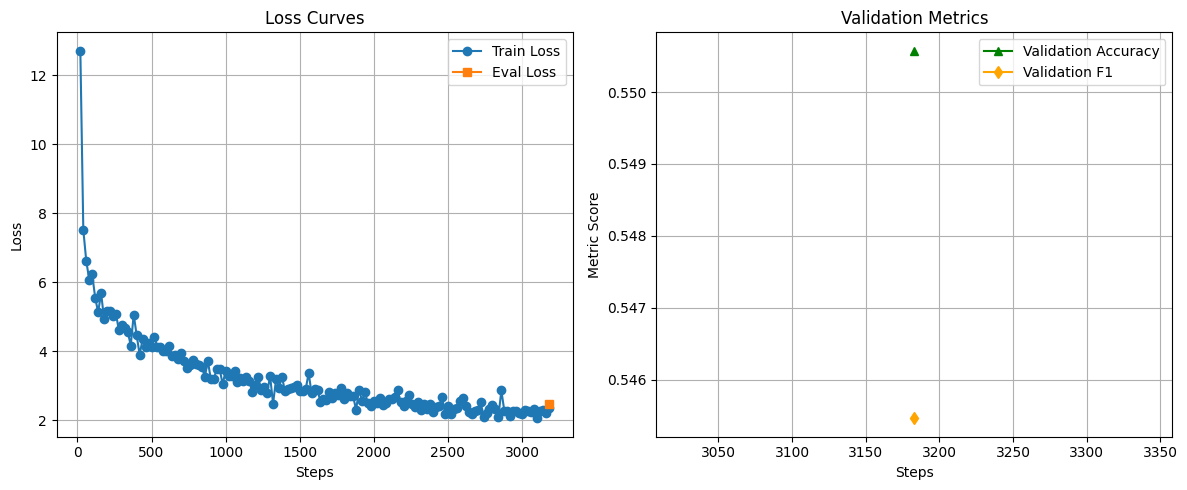

In [37]:
# 3. Plotting
plt.figure(figsize=(12, 5))

# Plot Loss if available
if not hist_train.empty or not eval_df.empty:
  plt.subplot(1, 2, 1)
  if not hist_train.empty:
    plt.plot(hist_train["step"], hist_train["loss"], label="Train Loss", marker="o")
  if not eval_df.empty:
    plt.plot(
        eval_df["step"], eval_df["eval_loss"], label="Eval Loss", marker="s"
    )
  plt.xlabel("Steps")
  plt.ylabel("Loss")
  plt.title("Loss Curves")
  plt.legend()
  plt.grid(True)

# Plot Validation Metrics (Accuracy / F1)
if not eval_df.empty:
  plt.subplot(1, 2, 2)
  if "eval_accuracy" in eval_df.columns:
    plt.plot(
        eval_df["step"],
        eval_df["eval_accuracy"],
        label="Validation Accuracy",
        marker="^",
        color="green",
    )
  if "eval_f1" in eval_df.columns:
    plt.plot(
        eval_df["step"],
        eval_df["eval_f1"],
        label="Validation F1",
        marker="d",
        color="orange",
    )
  plt.xlabel("Steps")
  plt.ylabel("Metric Score")
  plt.title("Validation Metrics")
  plt.legend()
  plt.grid(True)

plt.tight_layout()
plt.show()

In [38]:
# # Evaluate on the Test Dataset
# print("\n--- Evaluating on Test Set ---")
# test_results = trainer.evaluate(eval_dataset=tokenized_splits["validation"])
# print(test_results)

## Load the best saved model

In [39]:
# Extract the best checkpoint path from the trainer state
best_model_path = trainer.state.best_model_checkpoint

print("Best model checkpoint path:", best_model_path)
# Create a text-classification pipeline using your saved model
classifier = pipeline(
    "text-classification",
    model=best_model_path,
    device=device
)

print("Best model successfully loaded from:", best_model_path)

Best model checkpoint path: ./saved_model/checkpoint-3183


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Best model successfully loaded from: ./saved_model/checkpoint-3183


## Predictions

In [40]:
# Using train_df for testing
texts = train_df['text'].to_list()
true_labels = train_df['model'].to_list()
# Run predictions in batches
results = classifier(texts, batch_size=16)
predicted_labels = [res['label'] for res in results]

# Evaluate Accuracy
accuracy = accuracy_score(true_labels, predicted_labels)
print(f"\n--- Pipeline Evaluation Results ---")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(true_labels, predicted_labels, zero_division=0))


--- Pipeline Evaluation Results ---
Accuracy: 55.06%

Classification Report:
                        precision    recall  f1-score   support

        claude-fable-5       0.30      0.27      0.28       149
       claude-opus-4-6       0.57      0.81      0.67       150
       claude-opus-4-8       0.50      0.55      0.53       150
         claude-opus-5       0.76      0.69      0.72       150
       claude-sonnet-5       0.64      0.65      0.65       150
gemini-3.1-pro-preview       0.83      0.85      0.84       150
      gemini-3.6-flash       0.75      0.73      0.74       150
      gemini-3.7-flash       0.56      0.39      0.46       150
      gemini-3.8-flash       0.54      0.67      0.60       150
               glm-5.3       0.38      0.15      0.22       150
         glm-5.3-flash       0.29      0.33      0.31       150
               gpt-5.5       0.47      0.51      0.49       150
          gpt-5.6-luna       0.55      0.50      0.52       150
           gpt-5.6-sol   

## Submission

In [41]:
TEST_PATH = (
    INPUT_DIR / "competitions/name-that-llm/test.csv"
)

test_df = pd.read_csv(TEST_PATH)
print("Original training shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
test_df.head()

Original training shape: (3, 2)
Columns: ['id', 'text']


,id,text
0,00353fb1c541,"The more efficiently we use a resource, the mo..."
1,005f5a9a6139,"The Stern-Gerlach experiment, performed in 192..."
2,0062a53d5487,"Hundreds of millions of years ago, fluctuating..."


In [42]:
results = classifier(test_df["text"].to_list(),  batch_size=16)

predicted_labels = [res['label'] for res in results]

# Submission
submission = pd.DataFrame({
    "id": test_df["id"].values,
    "model": predicted_labels
})

# Save
output_path = "/kaggle/working/submission.parquet"

submission.to_parquet(output_path, index=False)

print("\nSubmission preview:")
submission.head()


Submission preview:


,id,model
0,00353fb1c541,qwen3.8-max
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.1-pro-preview
